# How big is the fBVOC prescription artefact in FUT? Uncorrected vs corrected, source by source

**Why this notebook.** The FUT emission-source choice (`analysis/fut-fbvoc-emission-source-choice.ipynb`) shows only artefact-corrected contrasts (user 2026-11-06). This notebook keeps the comparison: for each prescribed-emission source, the **uncorrected** BVOC contrast followed by the **design-B corrected** one, so the size and pattern of the correction can be seen map by map. PD counterpart: `how_big_artefact_is_PD.ipynb`. Created 2026-11-06 (user request).

| Key | Contrast |
|---|---|
| uncorrected, source E | `LCC_FUT − LCC_FUT_fBVOC<E>` |
| corrected, source E (`…_corr`) | `LCC_FUT − (LCC_FUT_fBVOC<E> − CTRL_FUT_fBVOCctrlFUT + CTRL_FUT)` = uncorrected − art_FUT, year by year (derived fields per real pair, `fm.corrected_fbvoc`) |
| emissions only | `LCC_FUT_fBVOCctrlFUT − LCC_FUT_fBVOCctrlPD` (both prescribed: the artefact cancels, no corrected version) |
| **art_FUT** | `CTRL_FUT − CTRL_FUT_fBVOCctrlFUT` (the correction itself; interactive − prescribed, user 2026-11-07) |

Sources: CTRL_PD, CTRL_FUT, LCC_PD; LCC_FUT (design A, `LCC_FUT_fBVOClccFUT`) is added automatically once processed: its uncorrected row is art on LCC land (art_LCC), its corrected row art_LCC − art_CTRL = δ_FUT (FUT test of the design-B assumption, like δ_PD in the PD notebook).

**Data.** CO₂-fix (new-chain) runs, 2001–2014 (first 12 months dropped), `data/processed-data/postprocessing/<alias>_atm_<CLASS>_2001-2014.nc`. Maps: mean over years; each panel its own colour scale; hatched = not significant (paired yearly t-test, FDR); under each map the area-weighted mean ≥45°N ± 95 % CI of the yearly means. Outputs: `how_big_artefact_is_FUT_outputs/`.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt

REPO = Path('/cluster/home/adelez/BOREAL-FOREST-EXPANSION')
sys.path.insert(0, str(REPO / 'src'))
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm

set_default_style()
START_YEAR, END_YEAR = 2001, 2014
OUT = Path('how_big_artefact_is_FUT_outputs')
FIGDIR = OUT / 'figures'
FIGDIR.mkdir(parents=True, exist_ok=True)

LCC, CTRL = 'LCC_FUT', 'CTRL_FUT'
ART = (CTRL, 'CTRL_FUT_fBVOCctrlFUT')   # art_FUT = interactive − prescribed (user 2026-11-07)
SOURCES = {'CTRL_PD': 'LCC_FUT_fBVOCctrlPD', 'CTRL_FUT': 'LCC_FUT_fBVOCctrlFUT',
           'LCC_PD': 'LCC_FUT_fBVOClccPD', 'LCC_FUT': 'LCC_FUT_fBVOClccFUT'}
# keep only sources whose processed files exist (LCC_FUT_fBVOClccFUT not run yet)
SOURCES = {s: a for s, a in SOURCES.items()
           if all(fm.filename(a, c, START_YEAR, END_YEAR).exists() for c in ('BVOC', 'SOA', 'RADIATIVE'))}
SRC_DIFF = ('LCC_FUT_fBVOCctrlFUT', 'LCC_FUT_fBVOCctrlPD')   # emissions only, artefact cancels

# every uncorrected row followed by its corrected one (user 2026-11-06), then emissions-only, then art_FUT
ROWS = []
for s, a in SOURCES.items():
    ROWS += [(LCC, a), (LCC, fm.corrected_fbvoc('FUT', a[len('LCC_FUT_fBVOC'):]))]
ROWS += [SRC_DIFF, ART]

for alias in sorted({LCC, *SOURCES.values(), *ART}):
    for cls in ('BVOC', 'SOA', 'RADIATIVE'):
        p = fm.filename(alias, cls, START_YEAR, END_YEAR)
        print(f'{p.name:55s}', '✓' if p.exists() else 'MISSING')
print('Sources used:', list(SOURCES))
for c1, c2 in ROWS:
    print(f'  {c1} − {c2}')

CTRL_FUT_atm_BVOC_2001-2014.nc                          ✓
CTRL_FUT_atm_SOA_2001-2014.nc                           ✓
CTRL_FUT_atm_RADIATIVE_2001-2014.nc                     ✓
CTRL_FUT_fBVOCctrlFUT_atm_BVOC_2001-2014.nc             ✓
CTRL_FUT_fBVOCctrlFUT_atm_SOA_2001-2014.nc              ✓
CTRL_FUT_fBVOCctrlFUT_atm_RADIATIVE_2001-2014.nc        ✓
LCC_FUT_atm_BVOC_2001-2014.nc                           ✓
LCC_FUT_atm_SOA_2001-2014.nc                            ✓
LCC_FUT_atm_RADIATIVE_2001-2014.nc                      ✓
LCC_FUT_fBVOCctrlFUT_atm_BVOC_2001-2014.nc              ✓
LCC_FUT_fBVOCctrlFUT_atm_SOA_2001-2014.nc               ✓
LCC_FUT_fBVOCctrlFUT_atm_RADIATIVE_2001-2014.nc         ✓
LCC_FUT_fBVOCctrlPD_atm_BVOC_2001-2014.nc               ✓
LCC_FUT_fBVOCctrlPD_atm_SOA_2001-2014.nc                ✓
LCC_FUT_fBVOCctrlPD_atm_RADIATIVE_2001-2014.nc          ✓
LCC_FUT_fBVOClccPD_atm_BVOC_2001-2014.nc                ✓
LCC_FUT_fBVOClccPD_atm_SOA_2001-2014.nc                 ✓
LCC_FUT_fBVOCl

## 1. BVOC → SOA → cloud maps: uncorrected, then corrected, per source
Same panels as section 3 of `analysis/fut-fbvoc-emission-source-choice.ipynb`. Pairs of rows: `LCC_FUT − fBVOC<E>` (uncorrected) then `… _corr` (design B). The difference uncorrected − corrected of a pair is art_FUT (last row).

findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


Saved how_big_artefact_is_FUT_outputs/figures/contrast_grid_context_FUT-artefact-uncorrected-vs-corrected_2001_2014.png


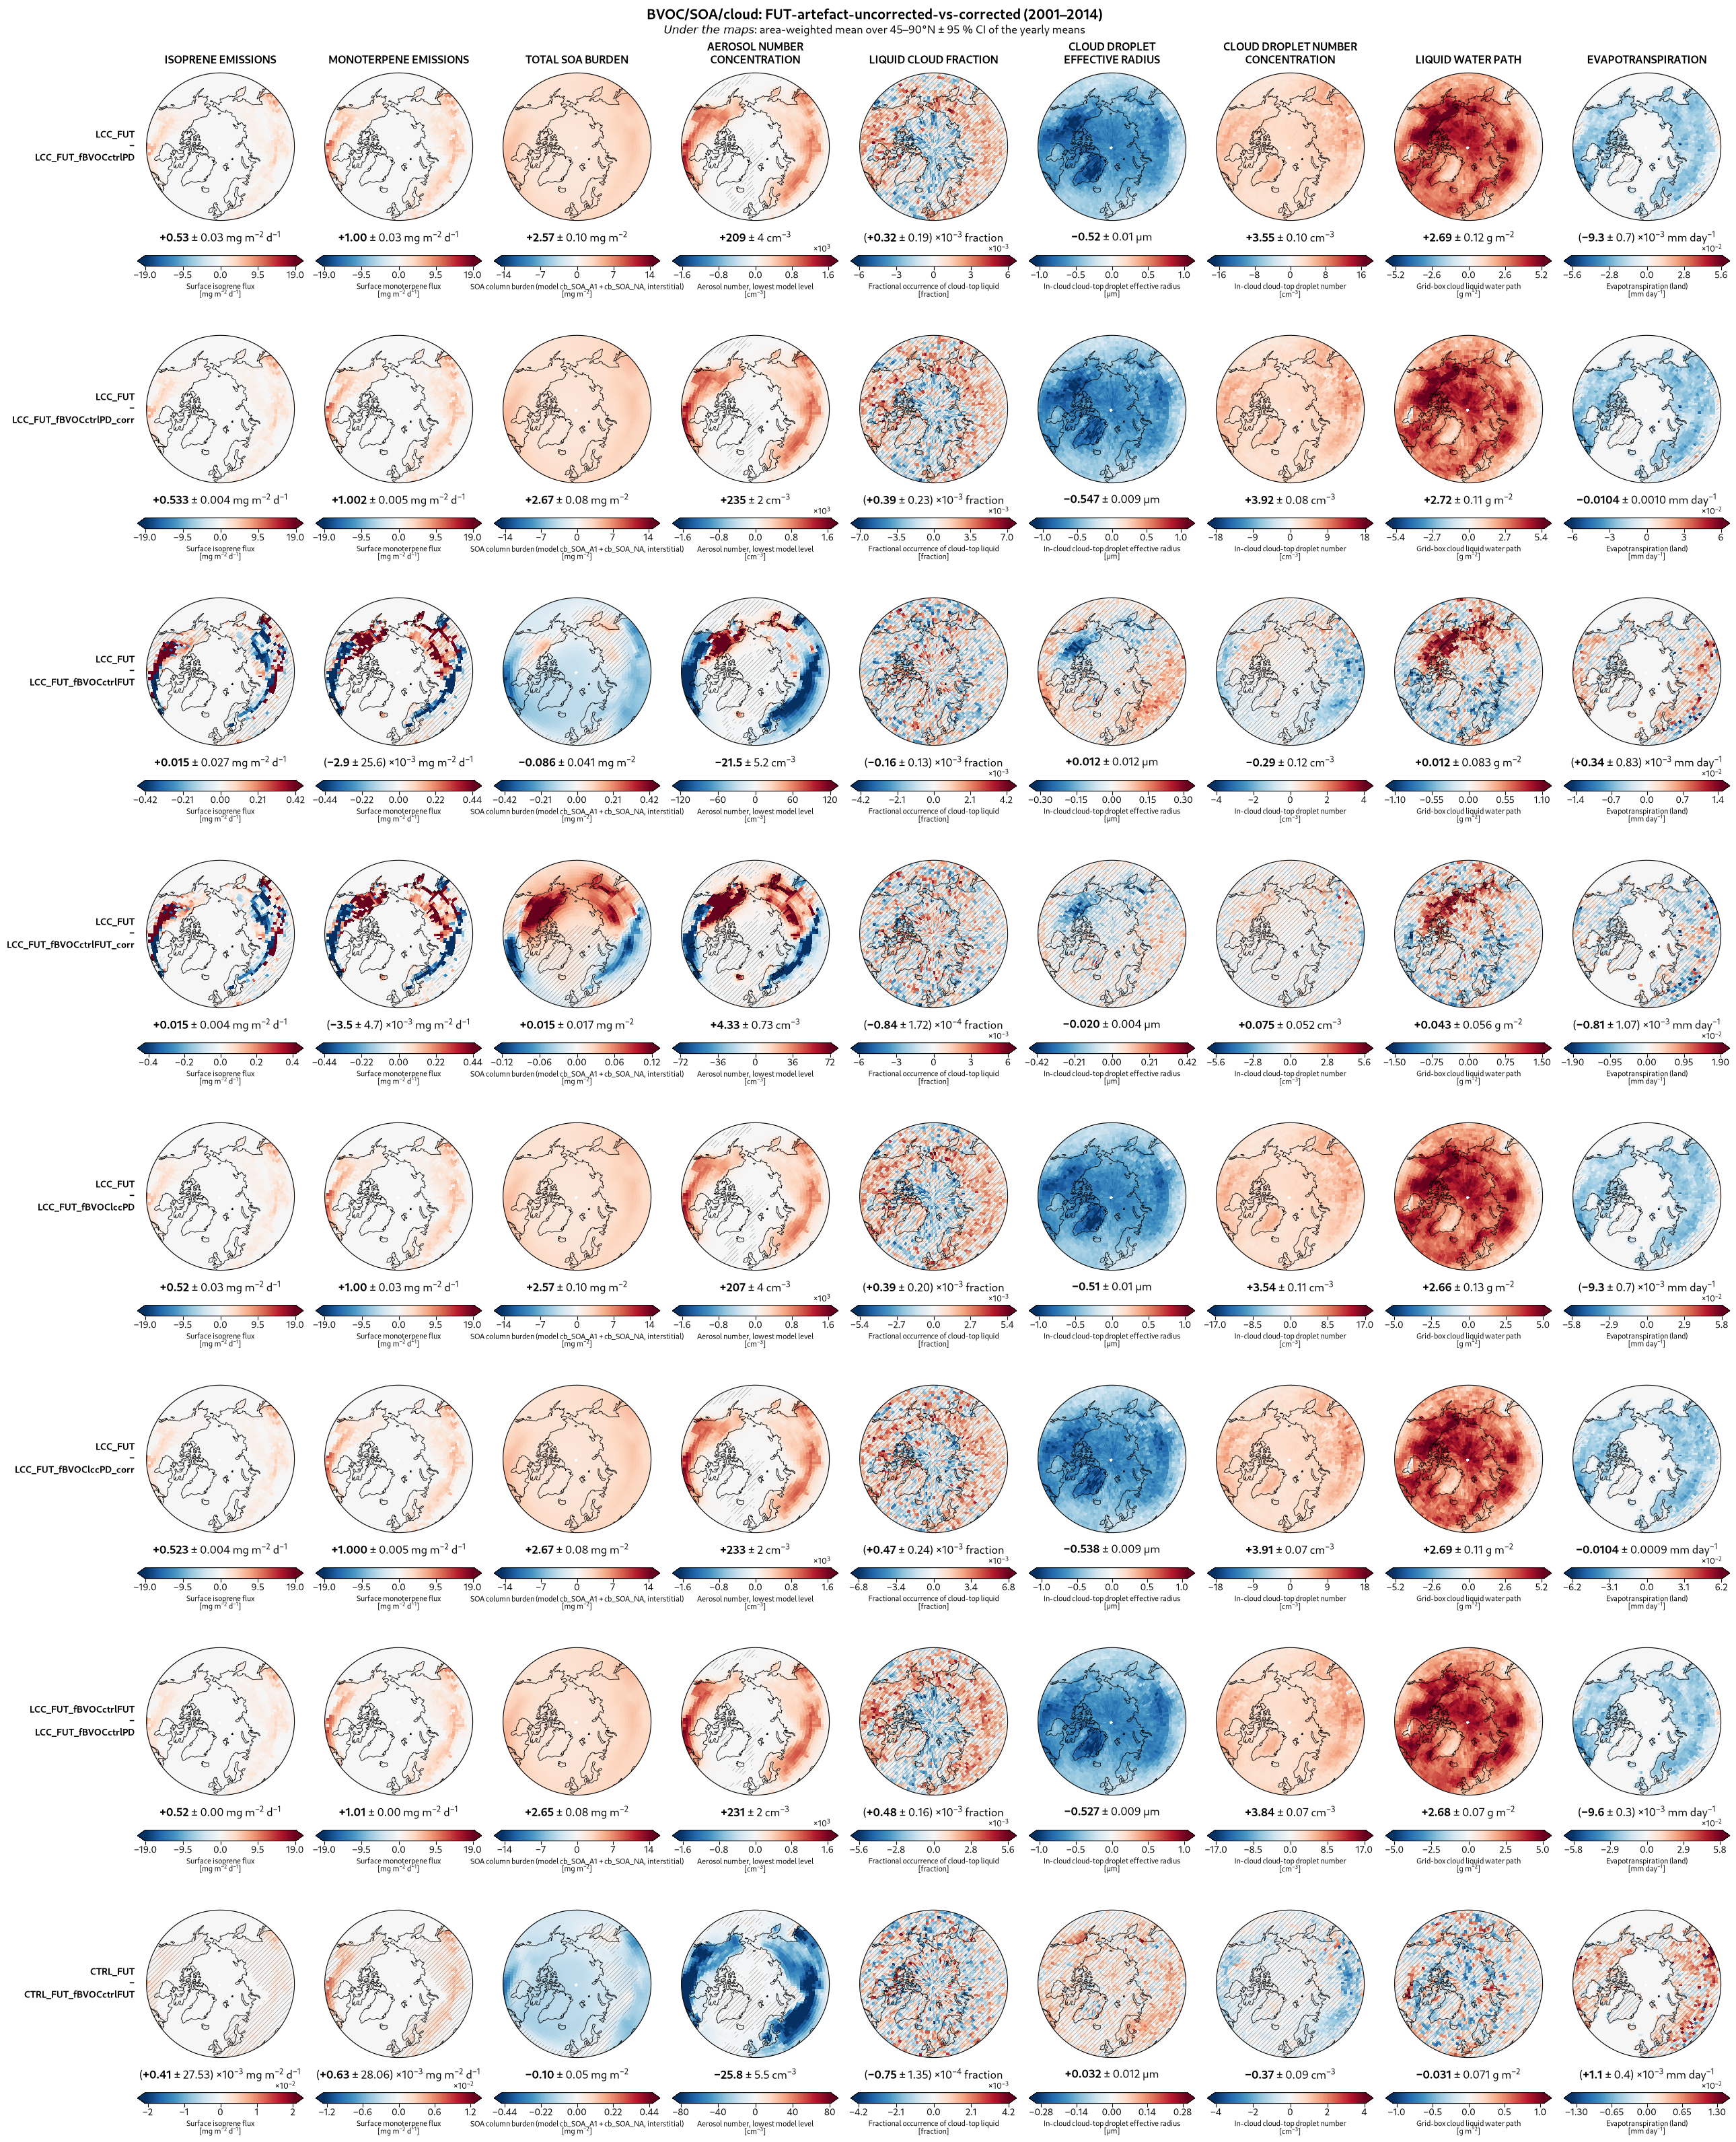

In [2]:
fig, axes = fm.make_contrast_grid_figure('FUT-artefact-uncorrected-vs-corrected', fm.CONTEXT_PANELS, 'context', rows=ROWS,
                                         start_year=START_YEAR, end_year=END_YEAR, figdir=FIGDIR)
plt.show(); plt.close(fig)